# Multi-Sample scRNA-Seq IMPROVED Re-analysis Pipeline - pt1 Exploratory analysis

IMPROVED, PATCHED AND AUTOMATED Reanalysis of: 
* Melms, J.C., Biermann, J., Huang, H. et al. A molecular single-cell lung atlas of lethal COVID-19. Nature 595, 114–119 (2021). https://doi.org/10.1038/s41586-021-03569-1

    - https://www.nature.com/articles/s41586-021-03569-1

    - download the "RAW.tar" data. GEO with accession number GSE171524

  **INCLUDES:**
  - Automated functions for plotting umaps
  - optimized scvi layers for analysis and plotting (normalization only in required data)
  - Step by step manual cell labeling and Biological interpretation

### **by José Alberto Isidoro Sánchez**

##### GUIDE: https://youtu.be/uvyG9yLuNSE?si=fzfICWtsWN2JSAaj

In [ ]:
#conda install scanpy


----------------
----------------
----------------
# Overview
-----------------
-----------------
-----------------

This repository contains an end-to-end processing pipeline for single-cell RNA sequencing (scRNA-seq) datasets using scvi-tools and scanpy. The workflow automates sample-level quality control, deep learning-based doublet removal, and multi-sample cohort integration to prepare raw single-cell count matrices for downstream biological analysis.  

Technical Workflow Steps
1. **Per-Sample Preprocessing & Doublet Detection (pt1)**
* Iterative Pipeline Execution: Each raw sequencing sample (.csv.gz or .h5ad) is processed individually to account for sample-specific library sizes and experimental batch effects.  
* Quality Filtering: Initial low-quality cell removal based on standard single-cell metrics (mitochondrial read percentage, minimum/maximum gene detection counts).
* Deep Learning Doublet Removal:
    * Fits a sample-specific Variational Autoencoder (scVI VAE) on unnormalized counts.
    * Trains a SOLO model (semi-supervised feed-forward neural network) using the learned VAE latent space to classify true single cells versus simulated doublets.
* Export Clean Artifacts: Filters out predicted doublets and saves purified sample objects as individual .h5ad files.  



2. **Cohort-Wide Integration & Downstream Analysis (pt2)**

* Merging: Aggregates purified, single-sample .h5ad objects into a unified, cohort-level AnnData object.
* Batch Integration: Retrains an integrated scVI generative model across all combined samples to remove technical batch effects while preserving true biological variation.
* Dimensionality Reduction & Clustering: Computes latent space embeddings (UMAP) and unsupervised graph-based clustering (Leiden/Louvain) for global cell-type annotation.




  
3. **Important Architectural Considerations**
Why Doublet Detection Runs Per Sample
* Doublets—microfluidic droplets that accidentally capture two or more cells—are artifact events dictated by the physical cell density and microfluidic loading conditions of an individual library preparation.
* Because doublet frequencies and expression profiles vary strictly by sample batch:
    * scVI and SOLO models are trained per sample. Training a single VAE/SOLO model across the whole cohort prior to integration leads to incorrect doublet classification.
    * Models are not applied across the entire cohort at once. Doublets must be identified and removed prior to cohort-wide batch correction and co-embedding.

----------------
----------------
----------------
## CREATE AN ENVIRONMENT:

----------------
----------------
----------------
----------------

To create a dedicated `bioinfo` Conda environment and set up Jupyter Notebooks, follow these step-by-step terminal commands.

1. **Create the Environment:** Command Line.
Open your terminal or Anaconda Prompt and create the environment named `bioinfo` with a specific Python version (e.g., Python 3.10):

```bash
conda create -n bioinfo python=3.10 -y

```


2. **Activate the Environment:** 1 sec.
Activate your newly created environment:

```bash
conda activate bioinfo

```

*Verification:* Your terminal prompt should now display `(bioinfo)` at the start of the line.


3. **Install Jupyter and ipykernel:** Packages.
Install Jupyter Notebook alongside `ipykernel`, which allows Jupyter to connect directly to this environment:

```bash
conda install -c conda-forge jupyter ipykernel -y

```

*Verification:* Run `jupyter --version` to ensure it is installed correctly.


4. **Register the Kernel with Jupyter:** Configuration.
Add the `bioinfo` environment as a recognizable kernel in Jupyter:

```bash
python -m ipykernel install --user --name=bioinfo --display-name "Python (bioinfo)"

```

*Verification:* Run `jupyter kernelspec list` to confirm that `"bioinfo"` is listed.


5. **Launch Jupyter Notebook:** Execution.
Start the Jupyter Notebook server from your terminal:

```bash
jupyter notebook

```

When the browser opens, go to **New** $\rightarrow$ select **Python (bioinfo)** to start working inside your new environment.



----------------
----------------
# Package Installation Rules for Notebooks
----------------
----------------

* **Terminal Conda (`conda install -c conda-forge`):** Use for heavy C/C++ or ML stack packages (`scvi-tools`, `pytorch`, `scanpy`). Prevents binary conflicts and OpenMP crashes on macOS ARM64.
* **`%pip install`:** Use inside notebooks for lightweight, pure-Python libraries (`seaborn`, `gseapy`, `statannotations`). Fast, kernel-safe, and won't affect core system C-libraries.
* **`%conda install -c conda-forge -y`:** Secondary option inside notebooks for C-dependent packages without switching to terminal.
* **`!pip` / `!conda` (Avoid):** Never use shell escapes (`!`). They bypass the active Jupyter kernel context and risk corrupting environment paths.


----------------
----------------

# 0.- ENVIRONMENT SETTINGS

----------------
----------------

In [4]:
#Check you are inside your environment. bioinfo in this case

#should print 'bioinfo' or your environment's name

import sys
print("Executable:", sys.executable) # Confirms .../envs/bioinfo/bin/python

# Prevent OpenMP runtime conflicts on macOS ARM64
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["OMP_NUM_THREADS"] = "1"

Executable: /opt/homebrew/Caskroom/miniconda/base/envs/bioinfo/bin/python


In [9]:
#conda install scanpy #do once then comment out with #import scanpy as sc

In [5]:
import scanpy as sc

# 1. Exploring Data structure

In [7]:
%pwd

'/Users/beto/progra25/covid19_single_cell_analysis'

In [40]:
#if you had the folders instead of the csv or the h5 matrix7, then use
adata = sc.read_csv('/Users/beto/progra25/covid19_single_cell_analysis/covid19_sc_data/GSE171524_RAW/GSM5226574_C51ctr_raw_counts.csv.gz').T 

#since scanpy requires columns to be genes and rows to be cells we use .T 
adata

SyntaxError: invalid syntax (2749237290.py, line 2)

In [16]:
adata.X.shape

(6099, 34546)

In [17]:
#we have 3 components of this adata object
adata.obs #just the cell barcodes
adata.var # it is the varaibles or genes
adata.X # the counts array

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(6099, 34546), dtype=float32)

# 1. PREPROCESSING
## 1.1 Doublet removal -optional but prefered
For single cell libraries, 2 or more cells an end up in the same droplet obscuring the sequencing.

-- needs to be done in individual samples and then integrate.

First, we are gonna train a model that can detect doublets


## 1.1.1 setting up data

In [14]:
# RUN ONCE THE FIRST TIME
#%conda install -c conda-forge scvi-tools -y


#### NOTE 

* **For Heavy ML & Bioinformatics Stack (`scvi-tools`, `pytorch`, `scanpy`):**
  Use `%conda install -c conda-forge <package_name> -y`

  
  * *Why:* Keeps PyTorch's C-libraries (`libomp`, OpenBLAS) synchronized with Conda's macOS arm64 binaries, preventing OpenMP library duplication and kernel crash segmentation faults.


* **For Lightweight, Pure-Python Libraries (`seaborn`, `gseapy`, `adjustText`):**
  Use `%pip install <package_name>`

  * *Why:* Installs pre-compiled PyPI wheels rapidly into the active kernel without running Conda's slow dependency solver.


* **Commands to AVOID inside Notebooks:**
  * **`!pip` / `!conda`**: Shell escapes (`!`) bypass the active Jupyter kernel context and often install packages into your `base` environment instead of `bioinfo`.

In [18]:
# 
!python --version
import sys
print("Active Python Executable:", sys.executable)
print("Python Version:", sys.version)

# 1. Activate your target environment
!conda activate bioinfo

# 2. Re-register the ipykernel spec specifically from inside the bioinfo env
!python -m ipykernel install --user --name bioinfo --display-name "Python (bioinfo)" --force

Python 3.14.6
Active Python Executable: /opt/homebrew/Caskroom/miniconda/base/envs/bioinfo/bin/python
Python Version: 3.10.21 | packaged by conda-forge | (main, Aug 21 2026, 22:37:53) [Clang 19.1.7 ]

CondaError: Run 'conda init' before 'conda activate'

usage: ipython-kernel-install [-h] [--user] [--name NAME]
                              [--display-name DISPLAY_NAME]
                              [--profile PROFILE] [--prefix PREFIX]
                              [--sys-prefix] [--env ENV VALUE]
                              [--frozen_modules]
ipython-kernel-install: error: unrecognized arguments: --force


In [16]:
### 

In [19]:
# Remember to restart the kernel to be able to import scvi
# 1. Import the package
import scvi


/opt/homebrew/Caskroom/miniconda/base/envs/bioinfo/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [20]:

# 2. Set seed for reproducibility
scvi.settings.seed = 0

Seed set to 0


In [21]:
#filter down genes:
#keep genes thata are found in at least 10 of the cells:
sc.pp.filter_genes(adata, min_cells=10)

In [22]:
adata
#down to 19896 genes now

AnnData object with n_obs × n_vars = 6099 × 19896
    var: 'n_cells'

In [23]:
#to run this, we need scikit-misc (run once, then comment out)
#%conda install -c conda-forge scikit-misc -y
# keep the 2000 top variable genes, which are the most representative of the
sc.pp.highly_variable_genes(adata, n_top_genes = 2000, subset = True, flavor = 'seurat_v3')

In [26]:
adata
# should be down to 2000 genes

AnnData object with n_obs × n_vars = 6099 × 2000
    var: 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg'

In [25]:
adata.var

,n_cells,highly_variable,highly_variable_rank,means,variances,variances_norm
TTLL10,112,True,903.0,0.028857,0.069354,1.901045
TNFRSF18,15,True,1604.0,0.002951,0.004911,1.513808
CFAP74,159,True,1370.0,0.041154,0.087024,1.607399
TTC34,209,True,245.0,0.080341,0.363502,3.044086
AJAP1,31,True,1922.0,0.006886,0.011432,1.421002
...,...,...,...,...,...,...
MT-ND4L,650,True,1212.0,0.191671,0.559353,1.695637
MT-ND4,1328,True,178.0,0.833087,9.742224,3.486984
MT-ND5,886,True,443.0,0.332514,1.669344,2.430210
MT-ND6,821,True,123.0,0.383178,3.357087,3.985056


### NOTES

- We need to install scikit-misc because, in the next command The seurat_v3 flavor uses LOESS smoothing, and the loess function is not part of the standard scientific Python stack—it's part of scikit-misc
- 

## 1.1.2 SCVI model to predict doublets

In [27]:
#1. create the model
scvi.model.SCVI.setup_anndata(adata) #default setup
vae = scvi.model.SCVI(adata) #vae is a model
vae.train(accelerator="mps")

## if it is the first time runnung, pass from "raw" to "code"

/opt/homebrew/Caskroom/miniconda/base/envs/bioinfo/lib/python3.10/site-packages/scvi/train/_trainrunner.py:69: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch/Jax operations are supported with this backend. as a result, some models might be slower and less accurate than usuall. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/opt/homebrew/Caskroom/miniconda/base/envs/bioinfo/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottlen

Epoch 400/400: 100%|█| 400/400 [04:57<00:00,  1.08it/s, v_num=1, train_loss_ste

`Trainer.fit` stopped: `max_epochs=400` reached.


Epoch 400/400: 100%|█| 400/400 [04:57<00:00,  1.34it/s, v_num=1, train_loss_ste


In [28]:
# train solo model which predicts doublets passing vae model
solo = scvi.external.SOLO.from_scvi_model(vae)
solo.train(accelerator="mps")

INFO     Creating doublets, preparing SOLO model.                                                                  


/opt/homebrew/Caskroom/miniconda/base/envs/bioinfo/lib/python3.10/site-packages/scvi/train/_trainrunner.py:69: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch/Jax operations are supported with this backend. as a result, some models might be slower and less accurate than usuall. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/opt/homebrew/Caskroom/miniconda/base/envs/bioinfo/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottlen

Epoch 175/400:  44%|▍| 175/400 [01:40<02:09,  1.74it/s, v_num=1, train_loss_ste
Monitored metric validation_loss did not improve in the last 30 records. Best score: 0.309. Signaling Trainer to stop.


##### -------------------------------------------------------------
##### NOTE: WHY SOLO MODEL CANT BE SAVED
##### -------------------------------------------------------------

* scvi.external.SOLO modifies adata internally when created via from_scvi_model(vae).

* During SOLO.from_scvi_model(vae), SOLO takes your VAE model and creates an internal adata object that contains both real cells and generated doublets, and it sets up 11 latent categorical registers. When you save solo.save(), it stores metadata expecting that modified internal structure. Passing your standard 2000-gene adata into SOLO.load() causes a validation crash (Expected: 11 Received: 2000).

* SOLO TRAINS RAPIDLY, JUST TRAIN IT AGAIN


### NOTE on VAE AND SOLO MODELS
- Step 1: scVI (The VAE) learns the biology.
Single-cell RNA-seq data is high-dimensional (20,000+ genes), sparse (lots of zero counts/dropout), and noisy. The VAE learns a low-dimensional latent space (usually 10–30 dimensions) that captures true biological signals, batch effects, and library size differences while smoothing out technical noise.

- Step 2: SOLO predicts doublets using those features.
SOLO is a binary classifier (Singlet vs. Doublet). Rather than trying to classify cells directly from 20,000 noisy gene counts, SOLO.from_scvi_model(vae) takes the encoder weights from your pre-trained scVI model. This allows SOLO to evaluate cells using the clean, compressed representations already learned by the VAE.

In [29]:
df = solo.predict()
#the higher the score, the higher the prediction
df['prediction'] = solo.predict(soft=False)
#df.index = df.index.map(lambda x: x[:-2]) #shorten the names
df

/opt/homebrew/Caskroom/miniconda/base/envs/bioinfo/lib/python3.10/site-packages/torch/utils/_contextlib.py:116: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabiltiies. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)
/opt/homebrew/Caskroom/miniconda/base/envs/bioinfo/lib/python3.10/site-packages/torch/utils/_contextlib.py:116: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabiltiies. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)


,doublet,singlet,prediction
TAGGTACCATGGCCAC-1_1,0.859777,0.140223,doublet
ATTCACTGTAACAGGC-1_1,0.956557,0.043443,doublet
TAACTTCCAACCACGC-1_1,0.876827,0.123173,doublet
TTGGGTACACGACAAG-1_1,0.876947,0.123053,doublet
AGGCCACAGAGTCACG-1_1,0.762252,0.237748,doublet
...,...,...,...
CGCCATTGTTTGCCGG-1_1,0.044030,0.955970,singlet
CACTGGGGTCTACGTA-1_1,0.001300,0.998700,singlet
CATACTTGTAGAGGAA-1_1,0.005292,0.994708,singlet
TTTGGTTTCCACGGAC-1_1,0.004466,0.995534,singlet


In [30]:
#check the predicted doublets and singlets
df.groupby('prediction').count()

,doublet,singlet
prediction,,
doublet,1169,1169
singlet,4930,4930


In [31]:
df['dif'] = df.doublet-df.singlet
df

,doublet,singlet,prediction,dif
TAGGTACCATGGCCAC-1_1,0.859777,0.140223,doublet,0.719555
ATTCACTGTAACAGGC-1_1,0.956557,0.043443,doublet,0.913114
TAACTTCCAACCACGC-1_1,0.876827,0.123173,doublet,0.753655
TTGGGTACACGACAAG-1_1,0.876947,0.123053,doublet,0.753894
AGGCCACAGAGTCACG-1_1,0.762252,0.237748,doublet,0.524503
...,...,...,...,...
CGCCATTGTTTGCCGG-1_1,0.044030,0.955970,singlet,-0.911940
CACTGGGGTCTACGTA-1_1,0.001300,0.998700,singlet,-0.997399
CATACTTGTAGAGGAA-1_1,0.005292,0.994708,singlet,-0.989416
TTTGGTTTCCACGGAC-1_1,0.004466,0.995534,singlet,-0.991068


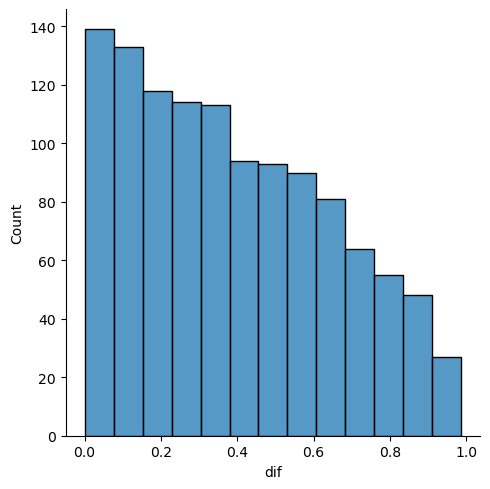

In [37]:
#plot distributions
import seaborn as sns
sns.displot(df[df.prediction == 'doublet'], x = 'dif')

We want to get rid of the doublets that area ambiguous, that is that their diff value is
close to 0: High positive dif (close to +1):
* Means the model is very confident the cell is a doublet
* P(doublet) ≈ 1, P(singlet) ≈ 0
* Highly reliable doublet prediction

Near-zero dif (e.g. between -0.2 and +0.2):
* The model is uncertain — probabilities are similar
* Could be either singlet or doublet
* Low-confidence prediction

High negative dif (close to -1):
* Model is very confident it's a singlet
* P(singlet) ≈ 1, P(doublet) ≈ 0
*Highly reliable singlet prediction

In [38]:
doublets = df[(df.prediction == 'doublet') & (df.dif>0.5)]
doublets

,doublet,singlet,prediction,dif
TAGGTACCATGGCCAC-1_1,0.859777,0.140223,doublet,0.719555
ATTCACTGTAACAGGC-1_1,0.956557,0.043443,doublet,0.913114
TAACTTCCAACCACGC-1_1,0.876827,0.123173,doublet,0.753655
TTGGGTACACGACAAG-1_1,0.876947,0.123053,doublet,0.753894
AGGCCACAGAGTCACG-1_1,0.762252,0.237748,doublet,0.524503
...,...,...,...,...
GGGTATTTCAGCGCAC-1_1,0.805398,0.194603,doublet,0.610795
GTTAGTGGTTCGGTTA-1_1,0.778342,0.221658,doublet,0.556684
TTGCTGCAGTGCGACA-1_1,0.758360,0.241640,doublet,0.516720
CATCCCAAGACGCCAA-1_1,0.903777,0.096223,doublet,0.807553


In [41]:


#if you had the folders instead of the csv or the h5 matrix7, then use
adata = sc.read_csv('/Users/beto/progra25/covid19_single_cell_analysis/covid19_sc_data/GSE171524_RAW/GSM5226574_C51ctr_raw_counts.csv.gz').T 

#since scanpy requires columns to be genes and rows to be cells we use .T 
adata


AnnData object with n_obs × n_vars = 6099 × 34546

In [42]:
overlapping = adata.obs.index.intersection(doublets.index)
print(len(overlapping))

405


In [43]:
adata.obs['doublet'] = adata.obs.index.isin(doublets.index)

In [44]:
adata.obs

,doublet
TAGGTACCATGGCCAC-1_1,True
ATTCACTGTAACAGGC-1_1,True
TAACTTCCAACCACGC-1_1,True
TTGGGTACACGACAAG-1_1,True
AGGCCACAGAGTCACG-1_1,True
...,...
CGCCATTGTTTGCCGG-1_1,False
CACTGGGGTCTACGTA-1_1,False
CATACTTGTAGAGGAA-1_1,False
TTTGGTTTCCACGGAC-1_1,False


In [45]:
adata.obs['doublet'].sum()

np.int64(405)

In [46]:
adata.obs['doublet'].any()

np.True_

In [47]:
#Now we keep only the false cells because True are doublets
adata = adata[~adata.obs.doublet]

In [48]:
adata
#went from 6099 cells to 5694

View of AnnData object with n_obs × n_vars = 5694 × 34546
    obs: 'doublet'

## 1.1.3 IDENTIFYING MITOCHONDRIAL GENES

In [49]:
adata.var[adata.var.index.str.startswith('MT-')]

""
MT-ND1
MT-ND2
MT-CO1
MT-CO2
MT-ATP8
MT-ATP6
MT-CO3
MT-ND3
MT-ND4L
MT-ND4


**Now lets annotate them as true or false**

In [50]:
adata.var['mt']= adata.var.index.str.startswith('MT-')
adata.var

/var/folders/w9/bwws86216wgb0hvxvlbzqqt40000gn/T/ipykernel_9385/738906307.py:1: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  adata.var['mt']= adata.var.index.str.startswith('MT-')


,mt
AL627309.1,False
AL627309.5,False
AL627309.4,False
AL669831.2,False
LINC01409,False
...,...
VN1R2,False
AL031676.1,False
SMIM34A,False
AL050402.1,False


In [51]:
# MT ones now appear annotated
adata.var[adata.var.index.str.startswith('MT-')]

,mt
MT-ND1,True
MT-ND2,True
MT-CO1,True
MT-CO2,True
MT-ATP8,True
MT-ATP6,True
MT-CO3,True
MT-ND3,True
MT-ND4L,True
MT-ND4,True


## ======================================== 
## 1.1.3 IDENTIFYING Ribosomal GENES

In [52]:
import pandas as pd

In [53]:
#LOAD RIBOSOME LIST
ribo_genes = pd.read_table("/Users/beto/progra25/covid19_single_cell_analysis/covid19_sc_data/kegg_ribosome_genes.txt", skiprows=2, header = None)

In [54]:
ribo_genes[0].values

array(['RPL10', 'RPL10A', 'RPL10L', 'RPL11', 'RPL12', 'RPL13', 'RPL13A',
       'RPL14', 'RPL15', 'RPL17', 'RPL18', 'RPL18A', 'RPL19', 'RPL21',
       'RPL22', 'RPL22L1', 'RPL23', 'RPL23A', 'RPL24', 'RPL26', 'RPL26L1',
       'RPL27', 'RPL27A', 'RPL28', 'RPL29', 'RPL3', 'RPL30', 'RPL31',
       'RPL32', 'RPL34', 'RPL35', 'RPL35A', 'RPL36', 'RPL36A', 'RPL36AL',
       'RPL37', 'RPL37A', 'RPL38', 'RPL39', 'RPL3L', 'RPL4', 'RPL41',
       'RPL5', 'RPL6', 'RPL7', 'RPL7A', 'RPL8', 'RPL9', 'RPLP0', 'RPLP1',
       'RPLP2', 'RPS10', 'RPS11', 'RPS12', 'RPS13', 'RPS15', 'RPS15A',
       'RPS16', 'RPS17', 'RPS18', 'RPS19', 'RPS2', 'RPS20', 'RPS21',
       'RPS23', 'RPS24', 'RPS25', 'RPS26', 'RPS27', 'RPS27A', 'RPS27L',
       'RPS28', 'RPS29', 'RPS3', 'RPS3A', 'RPS4X', 'RPS4Y1', 'RPS5',
       'RPS6', 'RPS7', 'RPS8', 'RPS9', 'RPSA', 'RSL24D1', 'RSL24D1P11',
       'UBA52'], dtype=object)

In [55]:
adata.var['ribo']= adata.var_names.isin(ribo_genes[0].values)

In [56]:
adata.var

,mt,ribo
AL627309.1,False,False
AL627309.5,False,False
AL627309.4,False,False
AL669831.2,False,False
LINC01409,False,False
...,...,...
VN1R2,False,False
AL031676.1,False,False
SMIM34A,False,False
AL050402.1,False,False


## ======================================== 
## 1.1.4 QUALITY CONTROL METRICS

In [57]:
#Calculating QC metrics
sc.pp.calculate_qc_metrics(adata, qc_vars=['mt','ribo'], percent_top=None, log1p=False, inplace=True)

In [58]:
adata.obs #this dataframe has been populated with qc metrics (statistics)
#percent of mitochondrial reads, number of positive genes, etc.

,doublet,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_ribo,pct_counts_ribo
TTACCGCCACTCAGAT-1_1,False,4144,11369.0,39.0,0.343038,5.0,0.043979
TTGGTTTTCCTAGCTC-1_1,False,3902,11472.0,463.0,4.035913,13.0,0.113319
TCTATCACAAGGCTTT-1_1,False,3582,8276.0,183.0,2.211213,5.0,0.060416
ATCCACCAGAGGTATT-1_1,False,3913,8286.0,191.0,2.305093,33.0,0.398262
CACTTCGCAGTACTAC-1_1,False,3244,8059.0,253.0,3.139347,14.0,0.173719
...,...,...,...,...,...,...,...
CGCCATTGTTTGCCGG-1_1,False,355,410.0,3.0,0.731707,0.0,0.000000
CACTGGGGTCTACGTA-1_1,False,346,403.0,0.0,0.000000,0.0,0.000000
CATACTTGTAGAGGAA-1_1,False,360,410.0,2.0,0.487805,0.0,0.000000
TTTGGTTTCCACGGAC-1_1,False,299,405.0,0.0,0.000000,2.0,0.493827


In [62]:
adata.var

,mt,ribo,n_cells_by_counts,mean_counts,pct_dropout_by_counts,total_counts
AL627309.1,False,False,7,0.001229,99.877064,7.0
AL627309.5,False,False,26,0.004566,99.543379,26.0
AL627309.4,False,False,4,0.000702,99.929751,4.0
AL669831.2,False,False,2,0.000351,99.964875,2.0
LINC01409,False,False,236,0.044784,95.855286,255.0
...,...,...,...,...,...,...
VN1R2,False,False,0,0.000000,100.000000,0.0
AL031676.1,False,False,0,0.000000,100.000000,0.0
SMIM34A,False,False,0,0.000000,100.000000,0.0
AL050402.1,False,False,0,0.000000,100.000000,0.0


In [63]:
adata.var.sort_values('n_cells_by_counts') 
# some genes were in almost every cell and some in almost none


,mt,ribo,n_cells_by_counts,mean_counts,pct_dropout_by_counts,total_counts
AL445072.1,False,False,0,0.000000,100.000000,0.0
AC008243.1,False,False,0,0.000000,100.000000,0.0
AC025614.2,False,False,0,0.000000,100.000000,0.0
NEUROG2,False,False,0,0.000000,100.000000,0.0
AC017007.5,False,False,0,0.000000,100.000000,0.0
...,...,...,...,...,...,...
AKAP13,False,False,4102,2.903583,27.959255,16533.0
MBNL1,False,False,4186,2.715139,26.484018,15460.0
NEAT1,False,False,4194,5.055497,26.343519,28786.0
ZBTB20,False,False,4327,2.455392,24.007727,13981.0


## ======================================== 
## 1.1.5 FILTERING BY TOTAL COUNTS & CELLS

##### FILTER BY genes in at least 3 cells

In [64]:
#lets see genes in at least 3 cells
sc.pp.filter_genes(adata, min_cells=3) #filter
adata.var.sort_values('n_cells_by_counts')  #visualize
#only 24146 rows genes

,mt,ribo,n_cells_by_counts,mean_counts,pct_dropout_by_counts,total_counts,n_cells
UGT1A4,False,False,3,0.000527,99.947313,3.0,3
AL133372.3,False,False,3,0.000527,99.947313,3.0,3
KCNJ9,False,False,3,0.000527,99.947313,3.0,3
GPR33,False,False,3,0.000527,99.947313,3.0,3
AL590560.5,False,False,3,0.000527,99.947313,3.0,3
...,...,...,...,...,...,...,...
AKAP13,False,False,4102,2.903583,27.959255,16533.0,4102
MBNL1,False,False,4186,2.715139,26.484018,15460.0,4186
NEAT1,False,False,4194,5.055497,26.343519,28786.0,4194
ZBTB20,False,False,4327,2.455392,24.007727,13981.0,4327



##### FILTER BY TOTAL COUNTS

In [65]:
adata.obs.sort_values('total_counts')
#lower counts 401.0 -- indicates pre filtered data by authors in 'total_counts'


,doublet,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_ribo,pct_counts_ribo
CTCAACCGTTTGGGAG-1_1,False,325,401.0,0.0,0.000000,0.0,0.000000
CAGGGCTTCATGCGGC-1_1,False,330,401.0,7.0,1.745636,1.0,0.249377
AGGCATTCATCCGTTC-1_1,False,290,401.0,1.0,0.249377,0.0,0.000000
TGGTACAGTTGGTGTT-1_1,False,323,401.0,0.0,0.000000,0.0,0.000000
CGAGAAGGTGAACTAA-1_1,False,308,401.0,0.0,0.000000,0.0,0.000000
...,...,...,...,...,...,...,...
CACTTCGCAGTACTAC-1_1,False,3244,8059.0,253.0,3.139347,14.0,0.173719
TCTATCACAAGGCTTT-1_1,False,3582,8276.0,183.0,2.211213,5.0,0.060416
ATCCACCAGAGGTATT-1_1,False,3913,8286.0,191.0,2.305093,33.0,0.398262
TTACCGCCACTCAGAT-1_1,False,4144,11369.0,39.0,0.343038,5.0,0.043979


In [56]:
#lerts check 'n_genes_by_counts',
adata.obs.sort_values('n_genes_by_counts')

# 200 would be a nice place to start but here we have more than that, no filtering needed (can be arbitrary, really)

,doublet,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_ribo,pct_counts_ribo
TAGGGTTTCTGGCTGG-1_1,False,276,419.0,1.0,0.238663,1.0,0.238663
CGTGCTTCAAAGGGCT-1_1,False,277,432.0,41.0,9.490741,0.0,0.000000
TGACAGTTCTAAACGC-1_1,False,278,414.0,0.0,0.000000,0.0,0.000000
CTCTGGTCACGACGAA-1_1,False,285,407.0,0.0,0.000000,0.0,0.000000
GTAAGTCGTATCGCGC-1_1,False,289,430.0,0.0,0.000000,0.0,0.000000
...,...,...,...,...,...,...,...
GGGTATTGTACGATGG-1_1,False,3362,7723.0,337.0,4.363589,6.0,0.077690
AAACGAAGTACAGAGC-1_1,False,3373,7181.0,132.0,1.838184,20.0,0.278513
TCTATCACAAGGCTTT-1_1,False,3582,8276.0,183.0,2.211213,5.0,0.060416
TTGGTTTTCCTAGCTC-1_1,False,3902,11472.0,463.0,4.035913,13.0,0.113319


## ======================================== 
## 1.1.6 VIZ QC METRICS & OUTLIER FILTERING

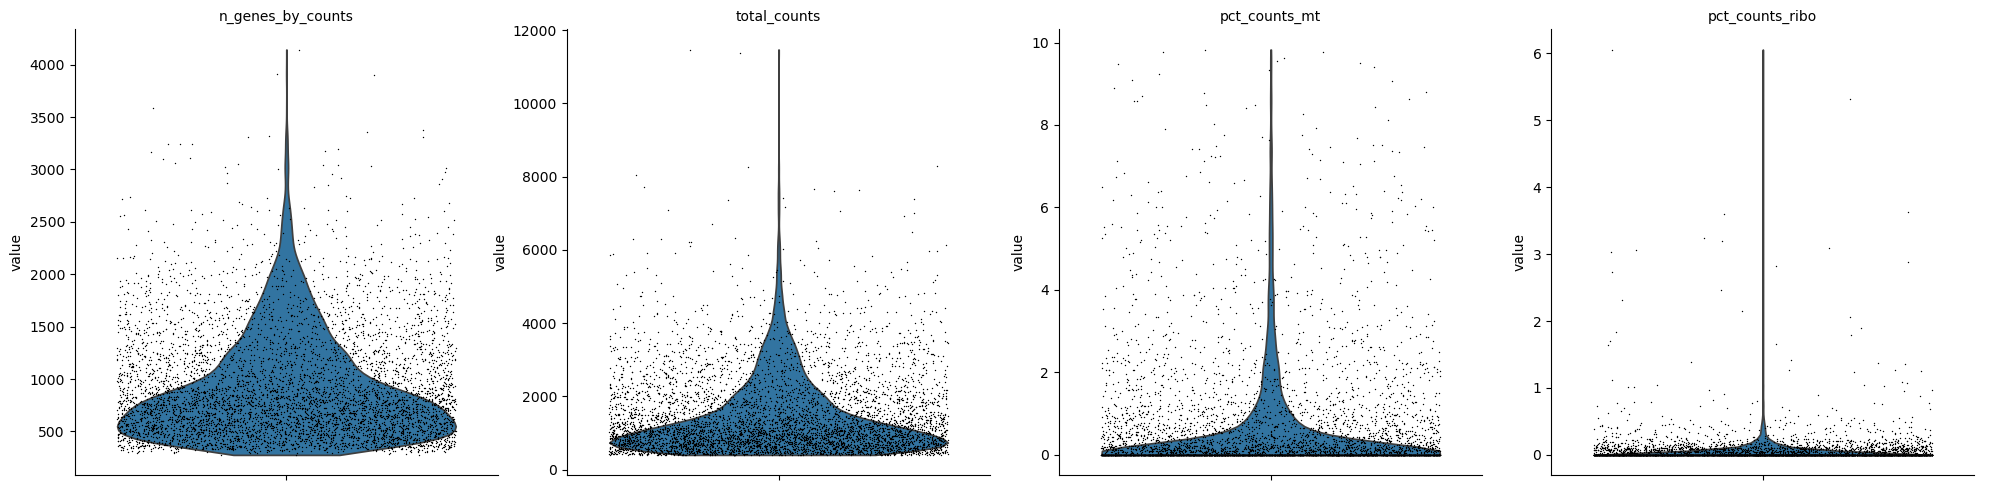

In [66]:
#We use this to get rid of outliers!!

sc.pl.violin(adata, ['n_genes_by_counts', 'total_counts', 'pct_counts_mt',
                     'pct_counts_ribo'], jitter=0.4, multi_panel=True)

* If a cell has significantly higher n_genes_by_counts or total_counts than average, chances are it is an outlier
* n_genes_by_counts or total_counts are both highly correlated so you can filter on either
* high mitochondrial pct could be sequencing artifacts o cells dying (usual filter 5-20%)
* ribo genes shows most around 0...


** CLEAN DATA BUT... We can filter out some outliers still**

In [67]:
import numpy as np

In [68]:
#WE ARE GONNA GET THE 98TH PERCENTILE OF N_GENES BY COUNT AND FILTER BY THAT... (INSTEAD OF PICKING A 300O VALUE ARBITRARILY)u
upper_lim = np.quantile(adata.obs.n_genes_by_counts.values, 0.98)
upper_lim

np.float64(2286.5600000000013)

In [69]:
#keep data (filter) below that limit
adata = adata[adata.obs.n_genes_by_counts < upper_lim]

In [70]:
adata.obs
#went down to 5498 individual sequenced cells (7 columns represent cell-level metadata metrics).

,doublet,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_ribo,pct_counts_ribo
CCTCAACCATACAGGG-1_1,False,2276,5434.0,38.0,0.699301,0.0,0.000000
ATACTTCCAAGGTCTT-1_1,False,2122,5252.0,1.0,0.019040,4.0,0.076161
GGGTCACTCTATTCGT-1_1,False,2286,5056.0,0.0,0.000000,1.0,0.019778
GATGATCCACAACCGC-1_1,False,2263,4938.0,2.0,0.040502,2.0,0.040502
GATAGCTCAGGCTTGC-1_1,False,2167,4879.0,0.0,0.000000,0.0,0.000000
...,...,...,...,...,...,...,...
CGCCATTGTTTGCCGG-1_1,False,355,410.0,3.0,0.731707,0.0,0.000000
CACTGGGGTCTACGTA-1_1,False,346,403.0,0.0,0.000000,0.0,0.000000
CATACTTGTAGAGGAA-1_1,False,360,410.0,2.0,0.487805,0.0,0.000000
TTTGGTTTCCACGGAC-1_1,False,299,405.0,0.0,0.000000,2.0,0.493827


In [71]:
#HOW TO FILTER ON MT COUNTS 
#here are very clean, less than 10, but the code is here anyways:
adata = adata[adata.obs.pct_counts_mt<20]

#wont change anything here
adata.obs

,doublet,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_ribo,pct_counts_ribo
CCTCAACCATACAGGG-1_1,False,2276,5434.0,38.0,0.699301,0.0,0.000000
ATACTTCCAAGGTCTT-1_1,False,2122,5252.0,1.0,0.019040,4.0,0.076161
GGGTCACTCTATTCGT-1_1,False,2286,5056.0,0.0,0.000000,1.0,0.019778
GATGATCCACAACCGC-1_1,False,2263,4938.0,2.0,0.040502,2.0,0.040502
GATAGCTCAGGCTTGC-1_1,False,2167,4879.0,0.0,0.000000,0.0,0.000000
...,...,...,...,...,...,...,...
CGCCATTGTTTGCCGG-1_1,False,355,410.0,3.0,0.731707,0.0,0.000000
CACTGGGGTCTACGTA-1_1,False,346,403.0,0.0,0.000000,0.0,0.000000
CATACTTGTAGAGGAA-1_1,False,360,410.0,2.0,0.487805,0.0,0.000000
TTTGGTTTCCACGGAC-1_1,False,299,405.0,0.0,0.000000,2.0,0.493827


,doublet,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_ribo,pct_counts_ribo
ATACTTCCAAGGTCTT-1_1,False,2122,5252.0,1.0,0.019040,4.0,0.076161
GATAGCTCAGGCTTGC-1_1,False,2167,4879.0,0.0,0.000000,0.0,0.000000
GACCCAGCACCCTATC-1_1,False,2150,4784.0,28.0,0.585284,4.0,0.083612
CATAAGCCACCCAACG-1_1,False,2126,4728.0,1.0,0.021151,2.0,0.042301
GATGACTGTACCCAGC-1_1,False,2007,4598.0,6.0,0.130492,3.0,0.065246
...,...,...,...,...,...,...,...
CGCCATTGTTTGCCGG-1_1,False,355,410.0,3.0,0.731707,0.0,0.000000
CACTGGGGTCTACGTA-1_1,False,346,403.0,0.0,0.000000,0.0,0.000000
CATACTTGTAGAGGAA-1_1,False,360,410.0,2.0,0.487805,0.0,0.000000
TTTGGTTTCCACGGAC-1_1,False,299,405.0,0.0,0.000000,2.0,0.493827


In [72]:
# filtering on RIBOSOMAL counts
adata = adata[adata.obs.pct_counts_ribo < 2]
#we are only getting rid off a few outliers
adata.obs

,doublet,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_ribo,pct_counts_ribo
CCTCAACCATACAGGG-1_1,False,2276,5434.0,38.0,0.699301,0.0,0.000000
ATACTTCCAAGGTCTT-1_1,False,2122,5252.0,1.0,0.019040,4.0,0.076161
GGGTCACTCTATTCGT-1_1,False,2286,5056.0,0.0,0.000000,1.0,0.019778
GATGATCCACAACCGC-1_1,False,2263,4938.0,2.0,0.040502,2.0,0.040502
GATAGCTCAGGCTTGC-1_1,False,2167,4879.0,0.0,0.000000,0.0,0.000000
...,...,...,...,...,...,...,...
CGCCATTGTTTGCCGG-1_1,False,355,410.0,3.0,0.731707,0.0,0.000000
CACTGGGGTCTACGTA-1_1,False,346,403.0,0.0,0.000000,0.0,0.000000
CATACTTGTAGAGGAA-1_1,False,360,410.0,2.0,0.487805,0.0,0.000000
TTTGGTTTCCACGGAC-1_1,False,299,405.0,0.0,0.000000,2.0,0.493827


#### RESULT: ADATA object OF DOUBLETS and OUTLIERS

In [73]:
#### ADATA object OF DOUBLETS and OUTLIERS
adata

View of AnnData object with n_obs × n_vars = 5564 × 24146
    obs: 'doublet', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo'
    var: 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'

## ======================================== 
## 1.1.7  ADATA CHECKPOINT ## ============================================
I can just load the saved adata and continue analysis from here

In [75]:
#Load the saved ADATA
adata = sc.read("/Users/beto/progra25/covid19_single_cell_analysis/covid19_sc_data/filter1_adata.h5ad")

## ======================================== 
## ======================================== 
## ======================================== 
# 2.- NORMALIZATION
## ======================================== 
## ======================================== 
## ======================================== 

Since we have lots ov variation between same cell types and other cells, just because of sequencing biases
So we need to normalize to compare cells and genes.

In [76]:
#Since we are starting again from here, we load all libraries.
import pandas as pd
import seaborn as sns
import scvi
import numpy as np

In [77]:
#Load the saved ADATA
adata = sc.read("/Users/beto/progra25/covid19_single_cell_analysis/covid19_sc_data/filter1_adata.h5ad")

In [79]:
#in adata each row is a cell here in the counts table, and each column a gen
adata.X

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 1., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(5564, 24146), dtype=float32)

In [73]:
adata.X.sum(axis =1)
#this gives the total counts for each cell

array([5250., 4877., 4783., ...,  410.,  405.,  410.],
      shape=(5483,), dtype=float32)

When sequencing cells, some cells just get sequenced more deeply than others — not
because they express more genes, but because of technical reasons like:
* how much RNA was captured from that cell
* differences in amplification efficiency
* sequencing machine variability

So the raw counts might show:
* Cell A → 5,000 total counts
* Cell B → 20,000 total counts

But those totals don’t necessarily mean Cell B is “more transcriptionally active.” It might
just be that more of Cell B’s RNA was captured or sequenced by chance.

In [80]:
#normalize every cell to 10,000
sc.pp.normalize_total(adata, target_sum = 1e4) 


In [81]:
adata.X.sum(axis =1) #now it will show the counts normalized for each cell

array([10000., 10000., 10000., ..., 10000., 10000., 10000.],
      shape=(5564,), dtype=float32)

In [82]:
#we convert to log counts, and they will not look the same after because
# it is not a lienar transformation but are more comaprible
sc.pp.log1p(adata) #change to log counts

In [83]:
adata.X.sum(axis = 1) #they are more comparable

array([3285.38  , 2858.1602, 3197.634 , ..., 1191.2706, 1022.7511,
       1162.8784], shape=(5564,), dtype=float32)

# Normalización y Transformación Logarítmica en Single-Cell RNA-seq

Entender la diferencia entre la **variación técnica** y la **variación biológica** es fundamental al analizar datos de *single-cell RNA-seq* (scRNA-seq).

---

## 1. ¿Por qué escalar la suma total a 10,000 (CP10K)?

En secuenciación de ARN célula a célula, los números absolutos de conteos (lecturas) **no representan una cantidad biológica absoluta**, sino la profundidad de secuenciación alcanzada por esa célula debido a factores técnicos.

Lo que realmente importa es la **abundancia relativa** (proporción) de un gen dentro de la célula:

* **Célula A:** $5,000$ lecturas totales. El **Gen X** tiene $50$ lecturas.
  $$\text{Proporción} = \frac{50}{5,000} = 0.01 \quad (1\% \text{ del ARN total})$$

* **Célula B:** $20,000$ lecturas totales (capturó más reactivo o se amplificó más). El **Gen X** tiene $200$ lecturas.
  $$\text{Proporción} = \frac{200}{20,000} = 0.01 \quad (1\% \text{ del ARN total})$$

> **Interpretación:** Ambas células expresan exactamente la misma proporción del Gen X. Comparar $50$ contra $200$ directamente crearía un falso positivo técnico.

### ¿Por qué elegimos el escalar $10,000$?
Escalar a $10,000$ (CP10K) simplemente multiplica la proporción por $10,000$ para evitar trabajar con decimales incómodos ($0.01 \to 100$).

$$\text{Célula A: } 0.01 \times 10,000 = 100$$
$$\text{Célula B: } 0.01 \times 10,000 = 100$$

> **Conclusión:** Escalar a $10,000$ con `sc.pp.normalize_total(adata, target_sum=1e4)` **elimina el sesgo técnico de profundidad** y preserva la proporción biológica real.

---

## 2. ¿Cómo funciona `log1p` sin alterar la biología?

La función `sc.pp.log1p(adata)` aplica la transformación $y = \ln(1 + x)$. Cumple dos funciones clave:

### A. Mantiene el orden biológico (Transformación Monótona)
El logaritmo **nunca altera el orden relativo** de los valores de expresión:
* Si $\text{Gen Y} > \text{Gen X}$ antes de log ($900 > 100$), seguirá siendo mayor después ($\approx 6.80 > 4.61$).
* Si dos células tienen la misma expresión ($100 = 100$), tendrán el mismo valor final ($\approx 4.61 = 4.61$).

### B. Comprime el rango dinámico y estabiliza la varianza
Sin el logaritmo, unos pocos genes masivamente expresados (e.g., ribosomales o mitocondriales) dominarían por completo los cálculos de distancia (PCA, UMAP, KNN), opacando cambios biológicos sutiles pero críticos en factores de transcripción o receptores.

| Escala | Gen de baja expresión (Apagado vs Encendido) | Gen de alta expresión (Variación técnica) |
| :--- | :---: | :---: |
| **Normalizado (Lineal)** | $2 \to 10 \quad (\Delta = 8)$ | $2,000 \to 2,500 \quad (\Delta = 500)$ |
| **`log1p` (Comprimido)** | $\ln(1+2) \approx 1.09 \ \to \ \ln(1+10) \approx 2.39$ | $\ln(1+2000) \approx 7.60 \ \to \ \ln(1+2500) \approx 7.82$ |

---

## 3. Demostración paso a paso

### Paso 1: Conteos Crudos (Raw Counts)
Profundidad de secuenciación desigual ($5,000$ vs $20,000$ lecturas totales).

| Gene | Célula A (5,000 total) | Célula B (20,000 total) |
| :--- | :---: | :---: |
| **Gen X** | 50 | 200 |
| **Gen Y** | 450 | 1,800 |
| **Total** | **5,000** | **20,000** |

### Paso 2: Normalización a $10,000$ (`sc.pp.normalize_total`)
Todas las células quedan escaladas a $10,000$ lecturas. Ambas son directamente comparables.

| Gene | Célula A (Normalizado) | Célula B (Normalizado) |
| :--- | :---: | :---: |
| **Gen X** | 100 | 100 |
| **Gen Y** | 900 | 900 |
| **Total** | **10,000** | **10,000** |

### Paso 3: Transformación Logarítmica (`sc.pp.log1p`)
Se aplica $\ln(1 + x)$ sobre la matriz normalizada.

| Gene | Célula A (`log1p`) | Célula B (`log1p`) |
| :--- | :---: | :---: |
| **Gen X** | $\ln(1 + 100) \approx 4.615$ | $\ln(1 + 100) \approx 4.615$ |
| **Gen Y** | $\ln(1 + 900) \approx 6.802$ | $\ln(1 + 900) \approx 6.802$ |

> **Nota final:** Tras aplicar `log1p()`, las sumas por fila ya no darán $10,000$ debido a la naturaleza no lineal del logaritmo, lo cual es matemáticamente correcto y esperado.

-- PREGUNTAR A DRA. CLAUDIA

In [84]:
#Freeze data before filtering on variable genes, 
# regressing data or scaling
adata.raw = adata

#saving inside raw data

## ======================================== 
## ======================================== 
## ======================================== 
# 3.- CLUSTERING
## ======================================== 
## ======================================== 
## ======================================== 

In single-cell RNA-seq, we start with ~20,000 genes measured across thousands of cells. Most of these genes are either expressed at low background levels or expressed uniformly across all cells (e.g., housekeeping genes). Analyzing 20,000 dimensions directly creates severe computational slowdowns, introduces massive technical noise, and suffers from the "curse of dimensionality."


Section 3 performs Feature Selection and Dimensionality Reduction:

1. Filter for the most informative genes (Highly Variable Genes).
2. Remove unwanted technical noise (sequencing depth, mitochondrial/ribosomal bias) and scale expression.
3. Compress the gene space into linear components (PCA).
4. Construct a cell-to-cell similarity graph (KNN Graph).
5. Project the complex graph into 2D space (UMAP) for visualization and cluster identification.

## 3.1. Feature Selection: Highly Variable Genes (HVGs)

In [85]:
# Select the top 2000 genes with the highest variance across cells
sc.pp.highly_variable_genes(adata, n_top_genes = 2000)

In [86]:
#we now have new columns such as "highly_variable", "means", "dispersion", etc
adata.var

,mt,ribo,n_cells_by_counts,mean_counts,pct_dropout_by_counts,total_counts,n_cells,highly_variable,means,dispersions,dispersions_norm
AL627309.1,False,False,7,0.001229,99.877064,7.0,7,True,0.010990,2.764101,1.260327
AL627309.5,False,False,26,0.004566,99.543379,26.0,26,False,0.028859,2.302445,-0.138221
AL627309.4,False,False,4,0.000702,99.929751,4.0,4,False,0.002496,1.702829,-1.954706
LINC01409,False,False,236,0.044784,95.855286,255.0,236,False,0.266021,2.329208,-0.057145
FAM87B,False,False,5,0.000878,99.912188,5.0,5,False,0.005782,1.924183,-1.284131
...,...,...,...,...,...,...,...,...,...,...,...
AL354822.1,False,False,121,0.021953,97.874956,125.0,121,False,0.156284,2.409504,0.186105
AL592183.1,False,False,880,0.183000,84.545135,1042.0,880,False,0.873124,2.506953,-0.382543
AC240274.1,False,False,140,0.025290,97.541272,144.0,140,False,0.151166,2.300978,-0.142665
AC007325.4,False,False,4,0.000702,99.929751,4.0,4,False,0.003000,1.579804,-2.327398


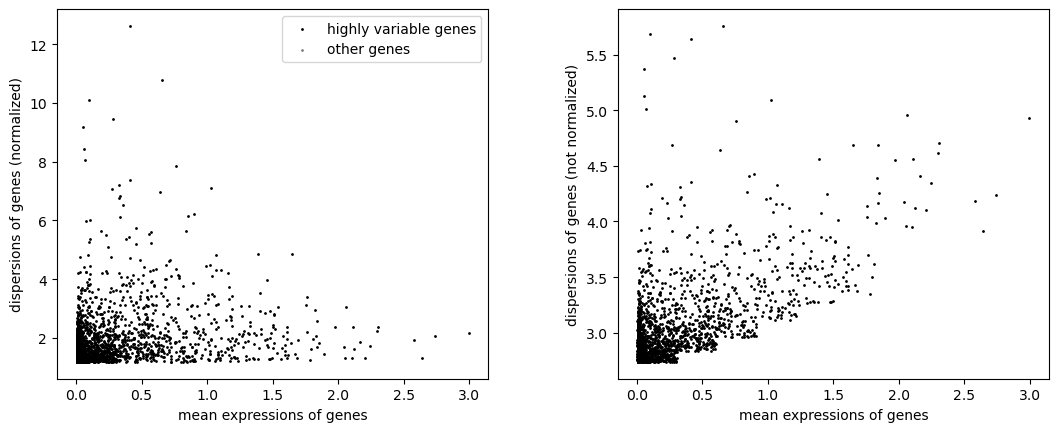

In [106]:
# Plot mean expression vs. dispersion (variance) to inspect selection
sc.pl.highly_variable_genes(adata)
#genes with higher dispersion are marked as highly variable genes
#we reduce dimension of data here 

sc.pp.highly_variable_genes(adata) → This creates new columns in adata.var like:
* highly_variable
* highly_variable_rank
* means
* variances
* dispersions
* etc.

→ sc.pl.highly_variable_genes() automatically uses those columns to plot:
* mean expression (x-axis)
* dispersion / variability (y-axis)
* highlights highly variable genes (usually in a different color

In [88]:
adata
#gives: AnnData object around n_obs × n_vars = 5483 × 23997

AnnData object with n_obs × n_vars = 5564 × 24146
    obs: 'doublet', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo'
    var: 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'log1p', 'hvg'

In [107]:
# Subset AnnData to retain ONLY the 2,000 HVGs
#filter out no highly variable genes. 
#This does not touch our raw data
adata = adata[:, adata.var.highly_variable]

In [90]:
adata
#Reduced to: n_obs × n_vars = 5483 × 2000

View of AnnData object with n_obs × n_vars = 5564 × 2000
    obs: 'doublet', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo'
    var: 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'log1p', 'hvg'

## 3.2 Technical Noise Removal & Scaling

### Now we regress differences that arise from total counts, pct_counts_mt, and pect_counts_ribo to get rid of variations on the data due to processing, sample quality, sequence artifacts, etc.

In [91]:
# Regress out unwanted technical sources of variation
sc.pp.regress_out(adata, ['total_counts','pct_counts_mt','pct_counts_ribo'])

/opt/homebrew/Caskroom/miniconda/base/envs/bioinfo/lib/python3.10/site-packages/scanpy/preprocessing/_simple.py:728: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


In [93]:
# Scale each gene to unit variance (Z-score) and clip outliers
#normalize each gene to unit variance
#of that same gene
sc.pp.scale(adata, max_value=10)

What it does:
* regress_out: Uses linear regression to subtract the effects of sequencing depth (total_counts), mitochondrial percentage (pct_counts_mt), and ribosomal percentage (pct_counts_ribo) from each gene's expression.
* scale: Standardizes expression values across cells so every gene has a mean of 0 and a variance of 1. Clips values $> 10$ to prevent extreme outliers from dominating.

Why:
* Without regress_out, cells might cluster by quality (e.g., dying cells with high mitochondrial content) rather than cell type.
* Without scale, highly expressed genes with massive raw counts would dominate downstream distance calculations simply due to their numerical scale, overriding lowly expressed but biologically crucial genes (like transcription factors).

## 3.3 Linear Dimensionality Reduction: PCA

In [94]:
#to further remove dimensions in data, 
# we perform principal component analysis
sc.tl.pca(adata, svd_solver='arpack') #20 pcs by default

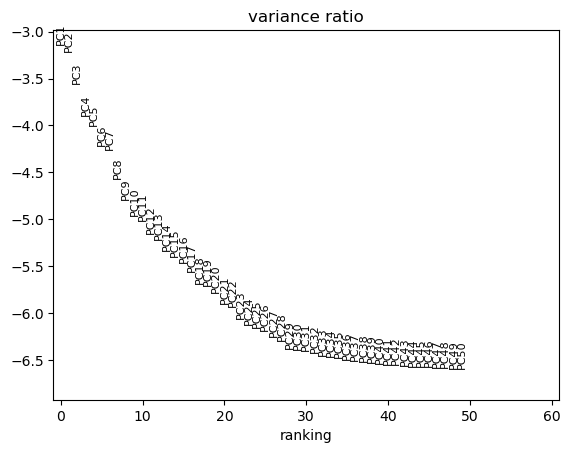

In [96]:
#plotting
sc.pl.pca_variance_ratio(adata, log=True, n_pcs=60)

#we want to search the elbow of the curve
# where the curve flattens as we increase the numer of n_pcs (x axis)

#At around 30, it starts to flatten out, we can pick 25 or 40 
#without much difference 
#In practice because we want the "elbow" of the plot


## 3.4. K-Nearest Neighbors (KNN) Graph Construction

High-dimensional Euclidean distance alone is insufficient for capturing complex non-linear cell relationships. Building a KNN graph constructs a local topological network of cell states, which serves as the foundation for clustering algorithms (e.g., Leiden) and 2D embeddings (UMAP).

In [108]:
# Compute cell-to-cell distances using the top 30 PCs
sc.pp.neighbors(adata, n_pcs=30)

# What it does: Measures the Euclidean distance between every 
# pair of cells in 30-dimensional PCA space and identifies
# the nearest $k$ neighbors for each cell.

In [109]:
adata #now we have - obsp: 'distances', 'connectivities'

AnnData object with n_obs × n_vars = 5564 × 2000
    obs: 'doublet', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'leiden'
    var: 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'log1p', 'hvg', 'pca', 'neighbors', 'umap', 'leiden', 'leiden_colors'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'

In [110]:
adata.obsp['connectivities']
# Weighted adjacency matrix representing graph connection strengths.

<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 114686 stored elements and shape (5564, 5564)>

In [111]:
adata.obsp['connectivities'].toarray() #Every connected cell will get a value
# Sparse matrix containing pairwise distances between neighbor cells.

array([[0.       , 0.       , 0.       , ..., 0.       , 0.       ,
        0.       ],
       [0.       , 0.       , 0.7549468, ..., 0.       , 0.       ,
        0.       ],
       [0.       , 0.7549468, 0.       , ..., 0.       , 0.       ,
        0.       ],
       ...,
       [0.       , 0.       , 0.       , ..., 0.       , 0.       ,
        0.       ],
       [0.       , 0.       , 0.       , ..., 0.       , 0.       ,
        0.       ],
       [0.       , 0.       , 0.       , ..., 0.       , 0.       ,
        0.       ]], shape=(5564, 5564), dtype=float32)

In [112]:
adata.obsp['distances'].toarray() 


array([[0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 4.45532846, ..., 0.        , 0.        ,
        0.        ],
       [0.        , 4.45532846, 0.        , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ]], shape=(5564, 5564))

### NOTE: THESE 2 NEIGHBOURHOOD MATRIX WILLB E USED TO DO CLUSTERING

## 3.5. Non-Linear Embedding: 2D UMAP Visualization

In [102]:
sc.tl.umap(adata) #to project the 30 pca dimenisonsinto 2

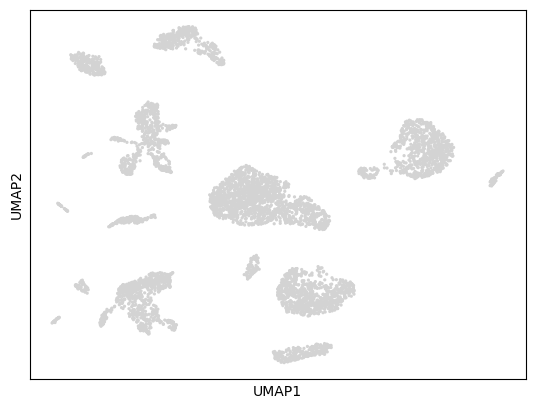

In [103]:
sc.pl.umap(adata)

### NOTE to assign lables to the data in this umap, we need the leidehalg algorithm: 
# % pip install leidenalg

In [105]:
%pip install leidenalg

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 12.4 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 35.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [leidenalg]
Note: you may need to restart the kernel to use updated packages.


In [104]:
#sc.tl.leiden(adata, resolution = 0.5)
sc.tl.leiden(adata, resolution=0.5, flavor="igraph", directed=False, n_iterations=2) ## newer default command
#resolution closer to 0 = fewer clusters
#resolution closer to 1 = more clusters

adata.obs

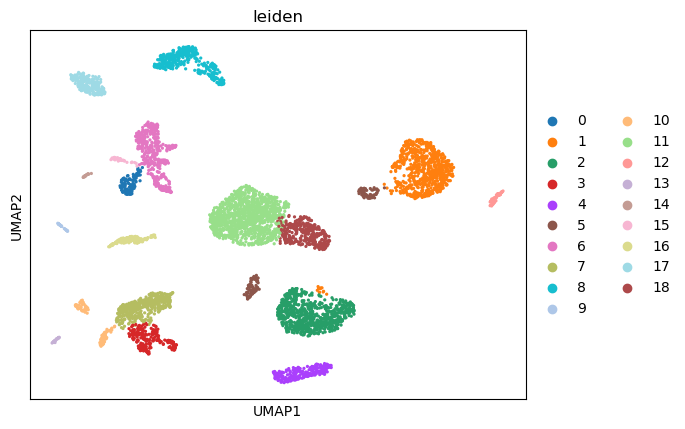

In [105]:
#Now we have our first sample clustered
sc.pl.umap(adata, color=['leiden'])
# NOTE: the leiden algorithem created a leiden colun inside adata.obs, that is what we use to color the cells for the umaps

## THIS IS THE END OF THE EXPLORATORY PART... LETS DO BATCH INTEGRATION IN THE NEXT PART (PART 2)
* lets do integration of multiple samples. 
* You can find markers with just one sample if you just have 1
* In this case we have many samples so nowe we have to integrate.

$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$

-----
-----
-----
-----
-----
-----
-----
-----


# 4. BATCH PROCESSING AND MERGING (BEFORE INTEGRATION)


-----
-----
-----
-----
-----
-----
-----
-----

$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$$

## 4.1 SETTING UP Batch Quality Control and Filtering

In [3]:
import os
import pandas as pd
import numpy as np
import scanpy as sc
import scvi
from scipy.sparse import csr_matrix

def pp(csv_path, n_epocs):
    # =========================================================================
    # SECTION 1: DOUBLET DETECTION SETUP & TRAINING
    # =========================================================================
    adata = sc.read_csv(csv_path).T
    
    # Filter genes and identify HVGs for SOLO
    sc.pp.filter_genes(adata, min_cells=10)
    sc.pp.highly_variable_genes(adata, n_top_genes=2000, subset=True, flavor='seurat_v3')
    
    # Train scVI VAE & SOLO doublet classifier on MPS
    scvi.model.SCVI.setup_anndata(adata)
    vae = scvi.model.SCVI(adata)
    vae.train(
   
        max_epochs= n_epocs,
        early_stopping=True,
        early_stopping_patience=15,
        accelerator="mps"
    )
    
    solo = scvi.external.SOLO.from_scvi_model(vae)
    solo.train(
        max_epochs=n_epochs,
        early_stopping=True,
        early_stopping_patience=15,
        accelerator="mps"    
    )

    # =========================================================================
    # SECTION 2: DOUBLET PREDICTION & FILTERING THRESHOLDS
    # =========================================================================
    df = solo.predict()
    df['prediction'] = solo.predict(soft=False)
    df.index = df.index.map(lambda x: x[:-2])
    df['dif'] = df.doublet - df.singlet
    
    doublets = df[(df.prediction == 'doublet') & (df.dif > 0.5)]

    # =========================================================================
    # SECTION 3: RE-LOADING RAW DATA & REMOVING IDENTIFIED DOUBLETS
    # =========================================================================
    # Reload pristine un-subsumed raw matrix
    adata = sc.read_csv(csv_path).T
    
    # Ensure CSR sparse format for memory efficiency
    if not isinstance(adata.X, csr_matrix):
        adata.X = csr_matrix(adata.X)

    # 🔒 CRITICAL FIX: Lock pure raw integer counts into 'counts' layer NOW
    adata.layers["counts"] = adata.X.copy()

    sample_name = os.path.basename(csv_path).replace('_raw_counts.csv', '')
    adata.obs['Sample'] = sample_name
    
    # Remove predicted doublets
    adata.obs['doublet'] = adata.obs.index.isin(doublets.index)
    adata = adata[~adata.obs.doublet].copy()

    # =========================================================================
    # SECTION 4: CELL QUALITY CONTROL (QC) METRICS ANNOTATION
    # =========================================================================
    sc.pp.filter_cells(adata, min_genes=200)
    
    adata.var['mt'] = adata.var_names.str.startswith('MT-')
    
    ribo_url = "http://software.broadinstitute.org/gsea/msigdb/download_geneset.jsp?geneSetName=KEGG_RIBOSOME&fileType=txt"
    ribo_genes = pd.read_table(ribo_url, skiprows=2, header=None)
    adata.var['ribo'] = adata.var_names.isin(ribo_genes[0].values)
    
    # QC metrics on unnormalized integers
    sc.pp.calculate_qc_metrics(adata, qc_vars=['mt', 'ribo'], percent_top=None, log1p=False, inplace=True)

    # =========================================================================
    # SECTION 5: OUTLIER FILTERING & FINAL CLEANUP
    # =========================================================================
    upper_lim = np.quantile(adata.obs.n_genes_by_counts.values, 0.98)
    adata = adata[adata.obs.n_genes_by_counts < upper_lim].copy()
    adata = adata[adata.obs.pct_counts_mt < 15].copy()
    adata = adata[adata.obs.pct_counts_ribo < 20].copy()
    
    return adata

/opt/homebrew/Caskroom/miniconda/base/envs/bioinfo/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## NOTE: using .copy in section 5 of the function:
Adding .copy() forces Python to allocate new memory and create an independent AnnData object.

Why this is critical in Scanpy / scRNA-seq pipelines:
1. Prevents ImplicitModificationWarning
* If you modify a view (e.g., adding downstream normalization, principal components, or clustering labels to adata.obs or adata.X), Scanpy will raise a runtime warning or error because you are attempting to mutate a slice of another object.

2. Frees Memory (Garbage Collection)
* When you filter out hundreds or thousands of low-quality cells, the underlying expression matrices (adata.X, adata.layers) remain anchored to the initial full-size dataset in RAM as long as the object is just a view. Calling .copy() creates a smaller, clean matrix containing only the remaining cells, allowing Python’s garbage collector to free up memory from the filtered-out doublets and dead cells.

3. Prevents Downstream Data Corruption
* Modifying an AnnData view in-place can inadvertently mutate the pre-filtered original array in unpredictable ways. .copy() breaks the link to the raw pre-QC matrix so downstream integration, dimensional reduction, and scaling run safely.

In [75]:
wd= %pwd
wd

'/Users/beto/progra25/covid19_single_cell_analysis'

In [76]:
#Run this quick snippet to confirm that the samples exist in the directory 
import os
input_dir = f'{wd}/covid19_sc_data/GSE171524_RAW/'
print("Files in directory:")
for f in os.listdir(input_dir):
    print(f)

Files in directory:
.DS_Store
GSM5226583_L04cov_raw_counts.csv.gz
GSM5226575_C52ctr_raw_counts.csv.gz
GSM5226582_L03cov_raw_counts.csv.gz
GSM5226574_C51ctr_raw_counts.csv.gz


---------
## 4.2 IMPLEMENTING Batch Quality Control and Filtering
---------

In [4]:
#IMPLEMENTING Batch Quality Control and Filtering¶
import gc
import os
import scanpy as sc

# Define working directory and correct subfolder path
wd = os.getcwd()
input_dir = os.path.join(wd, "covid19_sc_data", "GSE171524_RAW")
print("Input Directory: ", input_dir)

output_dir = os.path.join(wd, "covid19_sc_data", "processed")
os.makedirs(output_dir, exist_ok=True)
print("Output Directory:", output_dir)

# 1. Filter valid files
files_to_process = [
    f
    for f in os.listdir(input_dir)
    if not f.startswith("._") and f.lower().endswith(".csv.gz")
]
total_files = len(files_to_process)

print(f"\nFound {total_files} total files to process.\n")

# 2. Iterate with progress tracking and skip check
for idx, file in enumerate(files_to_process, start=1):
    csv_path = os.path.join(input_dir, file)

    # Clean sample identifier and define output file path
    sample_name = os.path.basename(csv_path).replace("_raw_counts.csv.gz", "")
    output_path = os.path.join(output_dir, f"{sample_name}.h5ad")

    # CHECK: Skip if destination .h5ad already exists
    if os.path.exists(output_path):
        print(
            f"Skipping ({idx}/{total_files}): {sample_name}.h5ad already exists."
        )
        continue

    print(f"Processing ({idx}/{total_files}): {file}...")

    # Execute preprocessing pipeline
    adata = pp(csv_path, n_epocs = 200)

    # Save to high-performance AnnData h5ad format
    adata.write(output_path)
    print(f"Saved ({idx}/{total_files}): {output_path}\n")

    # Explicit memory garbage collection
    del adata
    gc.collect()

print("🎉 All remaining files successfully processed and saved.")

Input Directory:  /Users/beto/progra25/covid19_single_cell_analysis/covid19_sc_data/GSE171524_RAW
Output Directory: /Users/beto/progra25/covid19_single_cell_analysis/covid19_sc_data/processed

Found 4 total files to process.

Processing (1/4): GSM5226583_L04cov_raw_counts.csv.gz...


/opt/homebrew/Caskroom/miniconda/base/envs/bioinfo/lib/python3.10/site-packages/scvi/train/_trainrunner.py:69: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch/Jax operations are supported with this backend. as a result, some models might be slower and less accurate than usuall. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/opt/homebrew/Caskroom/miniconda/base/envs/bioinfo/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottlen

Epoch 400/400: 100%|█| 400/400 [03:04<00:00,  2.30it/s, v_num=1, train_loss_ste

`Trainer.fit` stopped: `max_epochs=400` reached.


Epoch 400/400: 100%|█| 400/400 [03:04<00:00,  2.17it/s, v_num=1, train_loss_ste
INFO     Creating doublets, preparing SOLO model.                                                                  


/opt/homebrew/Caskroom/miniconda/base/envs/bioinfo/lib/python3.10/site-packages/scvi/train/_trainrunner.py:69: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch/Jax operations are supported with this backend. as a result, some models might be slower and less accurate than usuall. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/opt/homebrew/Caskroom/miniconda/base/envs/bioinfo/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottlen

... (7 outputs left out)

/opt/homebrew/Caskroom/miniconda/base/envs/bioinfo/lib/python3.10/site-packages/scvi/train/_trainrunner.py:69: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch/Jax operations are supported with this backend. as a result, some models might be slower and less accurate than usuall. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/opt/homebrew/Caskroom/miniconda/base/envs/bioinfo/lib/python3.10/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottlen

Epoch 220/400:  55%|▌| 220/400 [01:59<01:37,  1.85it/s, v_num=1, train_loss_ste
Monitored metric validation_loss did not improve in the last 30 records. Best score: 0.266. Signaling Trainer to stop.


/opt/homebrew/Caskroom/miniconda/base/envs/bioinfo/lib/python3.10/site-packages/torch/utils/_contextlib.py:116: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabiltiies. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)
/opt/homebrew/Caskroom/miniconda/base/envs/bioinfo/lib/python3.10/site-packages/torch/utils/_contextlib.py:116: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabiltiies. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)


Saved (4/4): /Users/beto/progra25/covid19_single_cell_analysis/covid19_sc_data/processed/GSM5226574_C51ctr.h5ad

🎉 All remaining files successfully processed and saved.


-----------------------------------

### NOTE OLD IMPLEMENTATION OF THE FUNCTION
-----------------

"""


OLDER VERSION: 

out = []

for file in os. listdir ('raw_counts/'):

    out append (pp(' raw_counts/' + file)) 

    
""""

--------------

The previous version had two critical issues that break when processing single-cell datasets at scale: RAM saturation and lack of persistence.

Key Improvements:
1. Prevents Memory Crashes (OOM Errors)

* Old: out.append(...) kept every processed AnnData object inside a single Python list in RAM simultaneously. With single-cell matrices, loading dozens of samples into memory quickly causes Out-Of-Memory (OOM) crashes or heavy swap usage.

* New: Processing one file at a time, calling del adata, and triggering gc.collect() explicitly clears the memory buffer after each sample finishes.

2. Per-Sample Disk Persistence (.h5ad)

* Old: Held everything in active Python memory without saving to disk. If the script crashed on sample 15 out of 20, all progress was lost.

* New: Writes each processed sample to .h5ad (HDF5-backed AnnData format). If execution breaks midway, completed samples remain safely saved on disk.

3. File Filter Safety

* Old: Processed every item in raw_counts/, including hidden system files like .DS_Store or non-data files.

* New: if not file.lower().endswith('.csv.gz'): continue guarantees that only valid target files pass into the preprocessing function.




---------
## 4.3 CONCATENATION & METADATA MERGING
---------

In [143]:
%pwd

'/Users/beto/progra25/covid19_single_cell_analysis'

In [5]:
import gc
import os
import anndata as ad
import scanpy as sc
from scipy.sparse import csr_matrix

# 0. Setting up Dirs
wd = os.getcwd()
input_dir = os.path.join(wd, "covid19_sc_data", "processed")
print("Input Directory: ", input_dir)

# Define output DIRECTORY and ensure it exists
output_dir = os.path.join(wd, "covid19_sc_data", "processed", "concatenated")
os.makedirs(output_dir, exist_ok=True)
print("Output Directory:", output_dir)

# Define output FILE path
output_path = os.path.join(output_dir, "combined_concat.h5ad")

# 1. Obtener la lista de archivos limpios
files = sorted(
    [
        os.path.join(input_dir, f)
        for f in os.listdir(input_dir)
        if f.endswith(".h5ad") and not f.startswith("._")
    ]
)

print(f"Archivos a concatenar: {len(files)}")

# 2. Cargar cada muestra optimizando memoria RAM
adatas = {}
for f in files:
    # Extraer ID limpio de la muestra (ej. "GSM5226574_C51ctr")
    sample_id = os.path.basename(f).replace(".h5ad", "")

    # Cargar archivo
    ad_temp = sc.read_h5ad(f)

    # Convertir X a CSR Sparse Matrix (Reduce el uso de RAM un ~70%)
    if not isinstance(ad_temp.X, csr_matrix):
        ad_temp.X = csr_matrix(ad_temp.X)

    # Limpiar capas innecesarias que consumen RAM
    ad_temp.uns.clear()
    ad_temp.obsm.clear()

    # Asignar la columna Sample explícitamente
    ad_temp.obs["Sample"] = sample_id
    adatas[sample_id] = ad_temp

print("\nConcatenando todas las muestras en un solo paso...")

# 3. Concatenación masiva en un solo paso
adata_combined = ad.concat(
    adatas, label="Sample", index_unique="_", merge="unique"
)

# Liberar memoria de los objetos individuales
del adatas
gc.collect()

# 4. Filtrado global de genes
sc.pp.filter_genes(adata_combined, min_cells=150)

# 5. Limpieza de nombres de Sample
adata_combined.obs["Sample"] = (
    adata_combined.obs["Sample"]
    .astype(str)
    .str.split("_")
    .str[-1]
    .astype("category")
)

# 6. Guardar archivo maestro
print(f"Guardando archivo final en: {output_path}")
adata_combined.write_h5ad(output_path)

print("🎉 Concatenación exitosa y guardada en SSD sin problemas de memoria.")

Input Directory:  /Users/beto/progra25/covid19_single_cell_analysis/covid19_sc_data/processed
Output Directory: /Users/beto/progra25/covid19_single_cell_analysis/covid19_sc_data/processed/concatenated
Archivos a concatenar: 4

Concatenando todas las muestras en un solo paso...
Guardando archivo final en: /Users/beto/progra25/covid19_single_cell_analysis/covid19_sc_data/processed/concatenated/combined_concat.h5ad
🎉 Concatenación exitosa y guardada en SSD sin problemas de memoria.


In [ ]:
# Concatenation with Automatic Metadata Deduplication
import gc
import os
import anndata as ad
import scanpy as sc
from scipy.sparse import csr_matrix
# 0. Setting up Dirs
wd = os.getcwd()
input_dir = os.path.join(wd, "covid19_sc_data", "processed")
print("Input Directory: ", input_dir)

# Define output DIRECTORY and ensure it exists
output_dir = os.path.join(wd, "covid19_sc_data", "processed", "concatenated")
os.makedirs(output_dir, exist_ok=True)
print("Output Directory:", output_dir)

# Define output FILE path
output_path = os.path.join(output_dir, "combined_concat.h5ad")

# 1. Obtener la lista de archivos limpios
files = sorted(
    [
        os.path.join(input_dir, f)
        for f in os.listdir(input_dir)
        if f.endswith(".h5ad") and not f.startswith("._")
    ]
)

print(f"Archivos a concatenar: {len(files)}")

# 2. Cargar cada muestra optimizando memoria RAM
adatas = {}
for f in files:
    # Extraer ID limpio de la muestra (ej. "GSM5226574_C51ctr")
    sample_id = os.path.basename(f).replace(".h5ad", "")

    # Cargar archivo
    ad_temp = sc.read_h5ad(f)

    # Convertir X a CSR Sparse Matrix (Reduce el uso de RAM un ~70%)
    if not isinstance(ad_temp.X, csr_matrix):
        ad_temp.X = csr_matrix(ad_temp.X)

    # Limpiar capas innecesarias que consumen RAM
    ad_temp.uns.clear()
    ad_temp.obsm.clear()

    # Asignar la columna Sample explícitamente
    ad_temp.obs["Sample"] = sample_id
    adatas[sample_id] = ad_temp

print("\nConcatenando todas las muestras en un solo paso...")

# 3. Concatenación masiva en un solo paso
adata_combined = ad.concat(
    adatas, label="Sample", index_unique="_", merge="unique"
)

# Liberar memoria de los objetos individuales
del adatas
gc.collect()

# =========================================================================
# CRITICAL FIX: ELIMINATE DUPLICATED OBS COLUMNS CREATED BY AD.CONCAT
# =========================================================================
if adata_combined.obs.columns.duplicated().any():
    print("Found duplicate columns in .obs post-concatenation. Deduplicating...")
    adata_combined.obs = adata_combined.obs.loc[
        :, ~adata_combined.obs.columns.duplicated()
    ].copy()

# 4. Filtrado global de genes
sc.pp.filter_genes(adata_combined, min_cells=150)

# 5. Limpieza y categorización de la columna 'Sample'
adata_combined.obs["Sample"] = (
    adata_combined.obs["Sample"]
    .astype(str)
    .str.split("_")
    .str[-1]
    .astype("category")
)

# 6. Guardar archivo maestro
print(f"Guardando archivo final en: {output_path}")
adata_combined.write_h5ad(output_path)

print("🎉 Concatenación exitosa y guardada en SSD sin problemas de memoria.")

$$$$$$$$$$$$$$$$

-------- 
## NOTA SOBRE PORQUE EL CAMBIO EN ESTA FORMA DE CONCATENAR:
* Matriz Dispersa (csr_matrix): Las matrices densas de $110,000 \text{ células} \times 20,000 \text{ genes}$ consumen en RAM más de 16 GB. Al forzar la conversión a csr_matrix, solo almacena los valores distintos de cero, reduciendo el consumo a menos de 2 GB.
* Un solo paso (ad.concat): Evita hacer sc.concat dentro de un bucle for (el cual creaba copias duplicadas de la matriz combinada en cada iteración y mataba el kernel).
* Limpieza previa (uns y obsm): Remueve cualquier matriz intermedia o cálculo previo de las muestras individuales para mantener el objeto maestro ligero antes del entrenamiento con scVI.
$$$$$$$$$$$$

---------
## 4.3.1 CHECKING DATA INTEGRITY AFTER CONCATENATION AND MERGING
---------

In [6]:
import pandas as pd
import os

# 0. Load the concatenated AnnData object 
wd = os.getcwd()
adata_path = os.path.join(wd, "covid19_sc_data", "processed", "concatenated",'combined_concat.h5ad')

print("Loading Concatenated ADATA from: ", adata_path)

# /Users/beto/progra25/covid19_single_cell_analysis/covid19_sc_data/processed/concatenated/combined_concat.h5ad

adata_combined = sc.read_h5ad(adata_path)

# 1. Inspect total cell counts per sample
print("Cell counts per sample:")
print(adata_combined.obs["Sample"].value_counts())

Loading Concatenated ADATA from:  /Users/beto/progra25/covid19_single_cell_analysis/covid19_sc_data/processed/concatenated/combined_concat.h5ad
Cell counts per sample:
Sample
C51ctr    5977
L03cov    4949
C52ctr    4422
L04cov    3557
Name: count, dtype: int64


In [7]:
# 2. Confirm unique sample count
total_samples = adata_combined.obs["Sample"].nunique()
print(f"\nTotal unique samples loaded: {total_samples} / Expected: 4")


Total unique samples loaded: 4 / Expected: 4


In [8]:
adata_combined.obs

,Sample,doublet,n_genes,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_ribo,pct_counts_ribo
CGTTCTGGTACTAGCT-1_1_GSM5226574_C51ctr,C51ctr,False,2434,2434,6047.0,6.0,0.099223,1.0,0.016537
CTGGCAGGTTCGGTAT-1_1_GSM5226574_C51ctr,C51ctr,False,2444,2444,5899.0,307.0,5.204272,5.0,0.084760
ACACCAACACAACGCC-1_1_GSM5226574_C51ctr,C51ctr,False,2451,2451,5497.0,0.0,0.000000,3.0,0.054575
CCTCAACCATACAGGG-1_1_GSM5226574_C51ctr,C51ctr,False,2276,2276,5434.0,38.0,0.699301,0.0,0.000000
ACAAAGATCCACAGGC-1_1_GSM5226574_C51ctr,C51ctr,False,2310,2310,5504.0,1.0,0.018169,1.0,0.018169
...,...,...,...,...,...,...,...,...,...
GTAGAGGTCAAAGGTA-1_10_GSM5226583_L04cov,L04cov,False,352,352,402.0,3.0,0.746269,6.0,1.492537
TTTGGAGCAGTTGTTG-1_10_GSM5226583_L04cov,L04cov,False,343,343,411.0,0.0,0.000000,0.0,0.000000
GGGACAACAAATACGA-1_10_GSM5226583_L04cov,L04cov,False,360,360,410.0,0.0,0.000000,0.0,0.000000
CTGTGGGAGAGTATAC-1_10_GSM5226583_L04cov,L04cov,False,349,349,407.0,0.0,0.000000,0.0,0.000000


In [9]:
# 1. Limpiar y categorizar la columna 'Sample'
adata_combined.obs["Sample"] = (
    adata_combined.obs["Sample"]
    .astype(str)
    .str.split("_")
    .str[-1]
    .astype("category")
)

# 2. Corregir y acortar los nombres de las células (obs_names)
adata_combined.obs_names = [
    f"{bc.split('_')[0]}_{sample}"
    for bc, sample in zip(adata_combined.obs_names, adata_combined.obs["Sample"])
]

# 3. Verificar el resultado
adata_combined.obs
    

,Sample,doublet,n_genes,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_ribo,pct_counts_ribo
CGTTCTGGTACTAGCT-1_C51ctr,C51ctr,False,2434,2434,6047.0,6.0,0.099223,1.0,0.016537
CTGGCAGGTTCGGTAT-1_C51ctr,C51ctr,False,2444,2444,5899.0,307.0,5.204272,5.0,0.084760
ACACCAACACAACGCC-1_C51ctr,C51ctr,False,2451,2451,5497.0,0.0,0.000000,3.0,0.054575
CCTCAACCATACAGGG-1_C51ctr,C51ctr,False,2276,2276,5434.0,38.0,0.699301,0.0,0.000000
ACAAAGATCCACAGGC-1_C51ctr,C51ctr,False,2310,2310,5504.0,1.0,0.018169,1.0,0.018169
...,...,...,...,...,...,...,...,...,...
GTAGAGGTCAAAGGTA-1_L04cov,L04cov,False,352,352,402.0,3.0,0.746269,6.0,1.492537
TTTGGAGCAGTTGTTG-1_L04cov,L04cov,False,343,343,411.0,0.0,0.000000,0.0,0.000000
GGGACAACAAATACGA-1_L04cov,L04cov,False,360,360,410.0,0.0,0.000000,0.0,0.000000
CTGTGGGAGAGTATAC-1_L04cov,L04cov,False,349,349,407.0,0.0,0.000000,0.0,0.000000


In [10]:
adata_combined.obs.groupby('Sample').count()

/var/folders/w9/bwws86216wgb0hvxvlbzqqt40000gn/T/ipykernel_69202/3579044919.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  adata_combined.obs.groupby('Sample').count()


,doublet,n_genes,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_ribo,pct_counts_ribo
Sample,,,,,,,,
C51ctr,5977,5977,5977,5977,5977,5977,5977,5977
C52ctr,4422,4422,4422,4422,4422,4422,4422,4422
L03cov,4949,4949,4949,4949,4949,4949,4949,4949
L04cov,3557,3557,3557,3557,3557,3557,3557,3557
